# 04 — Train and compare a two-branch retrieval model

**Question:** does symmetric paired-data contrastive training change retrieval
on geographically held-out fixture patches relative to the statistical baseline?

Two compact CNN branches handle 2 SAR and 4 selected optical channels, return
32-dimensional L2-normalized vectors, and train with symmetric InfoNCE. Nearby
off-diagonal pairs are excluded from negatives using projected coordinates.
Model selection uses validation recall; the test split is used only here for
final comparison. A fixed four-epoch CPU schedule makes this runnable quickly.
There is no reconstruction, translation, LLM, or evaluated semantic task.

In [1]:
from pathlib import Path
import json, sys, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/crosssense").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from crosssense.config import load_config, save_config
from crosssense.logging_config import configure_logging
from crosssense.data.synthetic import create_synthetic_fixture
from crosssense.data.pairing import prepare_pairs
from crosssense.data.dataset import load_manifest, load_pair_arrays, PairedPatchDataset
from crosssense.models.training import set_seed

config = load_config(ROOT / "configs/default.yaml")
config.training.device = "cpu"
set_seed(config.seed)
log_path = configure_logging(ROOT / "outputs/logs", "INFO", "notebook-04")
WORK = ROOT / "outputs/notebook_demo"
WORK.mkdir(parents=True, exist_ok=True)
save_config(config, WORK / "config.yaml")
scenes_path = WORK / "synthetic/scenes.csv"
if not scenes_path.exists():
    scenes_path = create_synthetic_fixture(WORK / "synthetic", config.data, config.seed)
manifest_path = WORK / "processed/pairs.csv"
if not manifest_path.exists():
    manifest_path = prepare_pairs(scenes_path, WORK / "processed", config.data, config.seed)
frame = load_manifest(manifest_path)
assert set(frame.source) == {"synthetic"}, "This default notebook is explicitly a synthetic demonstration"
display(Markdown("**SYNTHETIC PIPELINE TEST — no real satellite observations.**"))
display(pd.DataFrame([{"python": platform.python_version(), "numpy": version("numpy"), "torch": version("torch"), "rasterio": version("rasterio"), "seed": config.seed, "device": config.training.device}]))
display(config.to_dict())

**SYNTHETIC PIPELINE TEST — no real satellite observations.**

,python,numpy,torch,rasterio,seed,device
0,3.12.16,2.5.5,2.10.0,1.4.4,42,cpu


{'seed': 42,
 'data': {'patch_size': 32,
  'stride': 32,
  'resolution_m': 10.0,
  'target_crs': 'EPSG:32643',
  'sar_bands': [1, 2],
  'optical_bands': [2, 3, 4, 8],
  'sar_units': 'db',
  'sar_clip_db': [-30.0, 5.0],
  'optical_scale': 10000.0,
  'optical_clip': [0.0, 1.0],
  'min_valid_fraction': 0.8,
  'max_cloud_fraction': 0.2,
  'max_time_gap_days': 7.0,
  'min_overlap': 0.9,
  'geographic_exclusion_m': 500.0,
  'block_size_m': 10000.0,
  'split_buffer_m': 500.0,
  'split_fractions': [0.6, 0.2, 0.2],
  'scene_manifest': None,
  'require_cloud_mask': False,
  'allow_author_pairs_without_time': False},
 'model': {'sar_channels': 2,
  'optical_channels': 4,
  'embedding_dim': 32,
  'width': 16,
  'freeze_backbones': False},
 'training': {'batch_size': 8,
  'epochs': 4,
  'lr': 0.001,
  'temperature': 0.1,
  'device': 'cpu',
  'patience': 5,
  'num_workers': 0},
 'logging': {'level': 'INFO', 'output_dir': 'outputs/logs'}}

{'checkpoint_format': 1,
 'selected_epoch': 2,
 'training_config': {'seed': 42,
  'data': {'patch_size': 32,
   'stride': 32,
   'resolution_m': 10.0,
   'target_crs': 'EPSG:32643',
   'sar_bands': [1, 2],
   'optical_bands': [2, 3, 4, 8],
   'sar_units': 'db',
   'sar_clip_db': [-30.0, 5.0],
   'optical_scale': 10000.0,
   'optical_clip': [0.0, 1.0],
   'min_valid_fraction': 0.8,
   'max_cloud_fraction': 0.2,
   'max_time_gap_days': 7.0,
   'min_overlap': 0.9,
   'geographic_exclusion_m': 500.0,
   'block_size_m': 10000.0,
   'split_buffer_m': 500.0,
   'split_fractions': [0.6, 0.2, 0.2],
   'scene_manifest': None,
   'require_cloud_mask': False,
   'allow_author_pairs_without_time': False},
  'model': {'sar_channels': 2,
   'optical_channels': 4,
   'embedding_dim': 32,
   'width': 16,
   'freeze_backbones': False},
  'training': {'batch_size': 8,
   'epochs': 4,
   'lr': 0.001,
   'temperature': 0.1,
   'device': 'cpu',
   'patience': 5,
   'num_workers': 0},
  'logging': {'level': 

,epoch,loss,validation_recall@1,lr,elapsed_s,trained_pairs,skipped_singletons
0,1,1.829761,0.2500,0.001,0.053232,20,0
1,2,1.821539,0.3125,0.001,0.105494,20,0
2,3,1.737478,0.3125,0.001,0.152359,20,0
3,4,1.655654,0.2500,0.001,0.198164,20,0


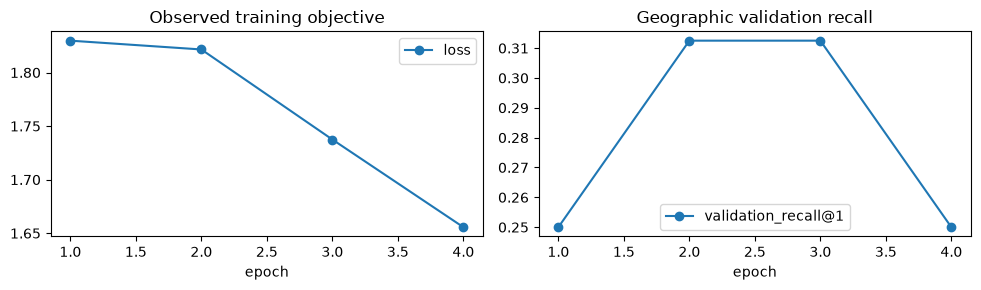

In [2]:
from crosssense.models.training import train_model, build_model, load_checkpoint
from crosssense.evaluation.reports import evaluate_experiment
config.training.epochs = 4
config.validate()
checkpoint = WORK / "train/best.pt"
if not checkpoint.exists():
    checkpoint = train_model(config, manifest_path, WORK / "train")
else:
    display(Markdown(f"Reusing existing local checkpoint `{checkpoint}`. Remove `outputs/notebook_demo/train` deliberately to rerun training from the same seed."))
payload = load_checkpoint(checkpoint, build_model(config))
display({"checkpoint_format": payload["format_version"], "selected_epoch": payload["epoch"], "training_config": payload["config"], "manifest_sha256": payload["manifest_sha256"]})
history = pd.read_json(WORK / "train/history.json")
display(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
history.plot(x="epoch", y="loss", ax=axes[0], marker="o")
history.plot(x="epoch", y="validation_recall@1", ax=axes[1], marker="o")
axes[0].set_title("Observed training objective"); axes[1].set_title("Geographic validation recall")
plt.tight_layout(); plt.show()

## Measured comparison in both retrieval directions

`evaluate_experiment` writes ranked retrieval CSVs, query ranks, JSON metrics,
HTML, embedding PCA and observed examples. Recall@K uses the exact positive ID;
MRR uses its full-gallery rank. Query-bootstrap intervals are conditional on this
gallery and do not represent spatial independence or repeated training seeds.
Latency excludes image loading/encoding and includes exact search/metadata return.
Small-gallery Recall@10 can be trivially 1 when the gallery has at most 10 items.

In [3]:
report_dir = WORK / "evaluation"
report = evaluate_experiment(config, manifest_path, checkpoint, report_dir)
assert report["data_label"] == "SYNTHETIC PIPELINE TEST"
display(pd.read_csv(report_dir / "summary.csv"))
display({"label": report["data_label"], "pairs": report["gallery_pairs"], "selected_epoch": report["selected_epoch"], "uncertainty_definition": report["uncertainty"]})
for method, directions in report["methods"].items():
    for direction, metrics in directions.items():
        display({"method": method, "direction": direction, "95% query-bootstrap": metrics["confidence_intervals_95"], "strata": metrics["strata"]})

,method,direction,recall@1,recall@5,recall@10,mrr,latency_ms_per_query,index_size_bytes
0,statistical_baseline,optical_to_sar,0.625,1.0,1.0,0.812500,0.017637,12759
1,statistical_baseline,sar_to_optical,0.625,1.0,1.0,0.791667,0.020288,12759
2,dual_encoder,optical_to_sar,0.250,1.0,1.0,0.531250,0.048275,13527
3,dual_encoder,sar_to_optical,0.250,1.0,1.0,0.541667,0.016850,13527


{'label': 'SYNTHETIC PIPELINE TEST',
 'pairs': 8,
 'selected_epoch': 2,
 'uncertainty_definition': '95% query-bootstrap percentile intervals, 200 resamples; conditional on this gallery, not spatial or training-seed confidence.'}

{'method': 'statistical_baseline',
 'direction': 'optical_to_sar',
 '95% query-bootstrap': {'recall@1': [0.25, 1.0],
  'recall@5': [1.0, 1.0],
  'recall@10': [1.0, 1.0],
  'mrr': [0.625, 1.0]},
 'strata': {'geographic_block': {'geo-2696bc3d57a6': {'queries': 4,
    'recall@1': 0.75,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.875},
   'geo-77d3bcd33968': {'queries': 4,
    'recall@1': 0.5,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.75}},
  'land_cover': {'synthetic_water': {'queries': 8,
    'recall@1': 0.625,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.8125}},
  'cloud_fraction': {'0-5%': {'queries': 8,
    'recall@1': 0.625,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.8125}},
  'time_gap_days': {'1-3': {'queries': 8,
    'recall@1': 0.625,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.8125}}}}

{'method': 'statistical_baseline',
 'direction': 'sar_to_optical',
 '95% query-bootstrap': {'recall@1': [0.25, 1.0],
  'recall@5': [1.0, 1.0],
  'recall@10': [1.0, 1.0],
  'mrr': [0.5833333333333333, 1.0]},
 'strata': {'geographic_block': {'geo-2696bc3d57a6': {'queries': 4,
    'recall@1': 0.5,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.7083333333333334},
   'geo-77d3bcd33968': {'queries': 4,
    'recall@1': 0.75,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.875}},
  'land_cover': {'synthetic_water': {'queries': 8,
    'recall@1': 0.625,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.7916666666666666}},
  'cloud_fraction': {'0-5%': {'queries': 8,
    'recall@1': 0.625,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.7916666666666666}},
  'time_gap_days': {'1-3': {'queries': 8,
    'recall@1': 0.625,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.7916666666666666}}}}

{'method': 'dual_encoder',
 'direction': 'optical_to_sar',
 '95% query-bootstrap': {'recall@1': [0.0, 0.625],
  'recall@5': [1.0, 1.0],
  'recall@10': [1.0, 1.0],
  'mrr': [0.3645833333333333, 0.7502604166666668]},
 'strata': {'geographic_block': {'geo-2696bc3d57a6': {'queries': 4,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.5416666666666666},
   'geo-77d3bcd33968': {'queries': 4,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.5208333333333334}},
  'land_cover': {'synthetic_water': {'queries': 8,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.53125}},
  'cloud_fraction': {'0-5%': {'queries': 8,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.53125}},
  'time_gap_days': {'1-3': {'queries': 8,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.53125}}}}

{'method': 'dual_encoder',
 'direction': 'sar_to_optical',
 '95% query-bootstrap': {'recall@1': [0.0, 0.625],
  'recall@5': [1.0, 1.0],
  'recall@10': [1.0, 1.0],
  'mrr': [0.3645833333333333, 0.7502604166666668]},
 'strata': {'geographic_block': {'geo-2696bc3d57a6': {'queries': 4,
    'recall@1': 0.5,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.7083333333333334},
   'geo-77d3bcd33968': {'queries': 4,
    'recall@1': 0.0,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.375}},
  'land_cover': {'synthetic_water': {'queries': 8,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.5416666666666666}},
  'cloud_fraction': {'0-5%': {'queries': 8,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.5416666666666666}},
  'time_gap_days': {'1-3': {'queries': 8,
    'recall@1': 0.25,
    'recall@5': 1.0,
    'recall@10': 1.0,
    'mrr': 0.5416666666666666}}}}

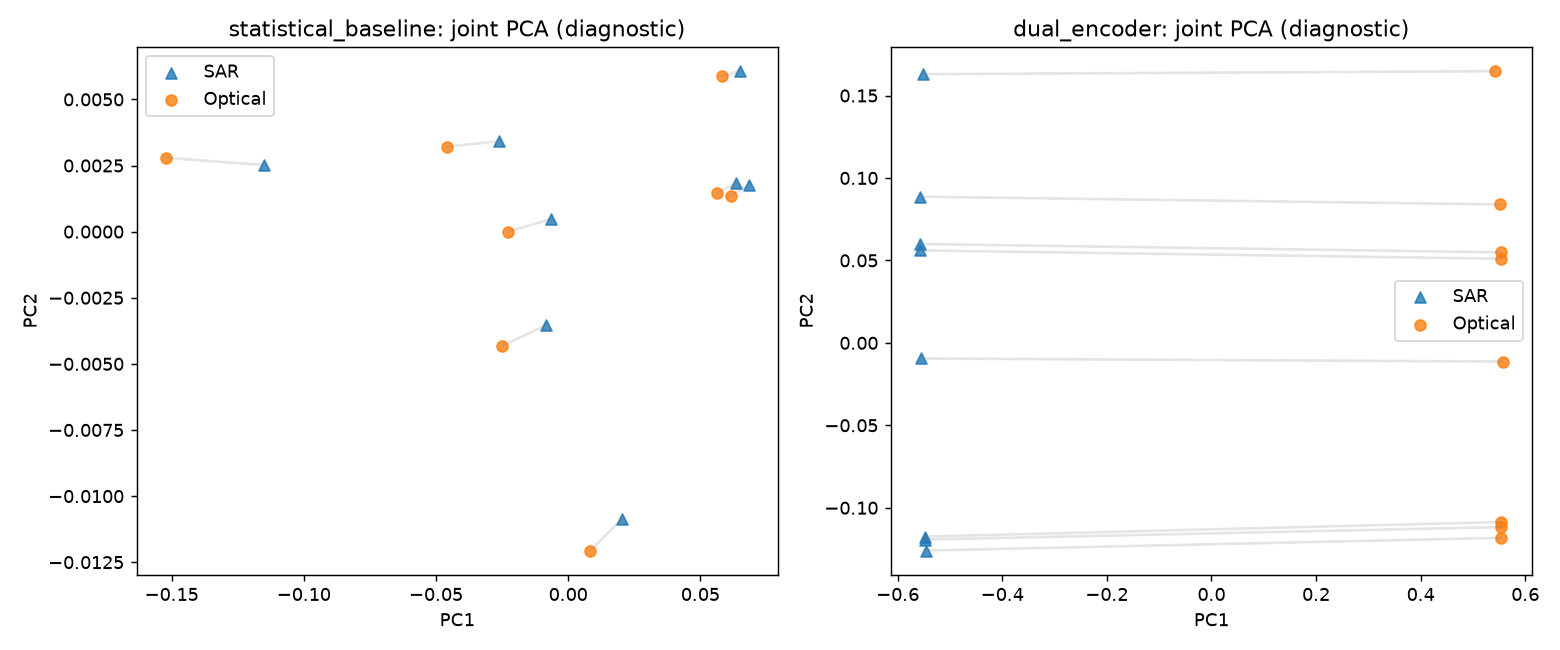

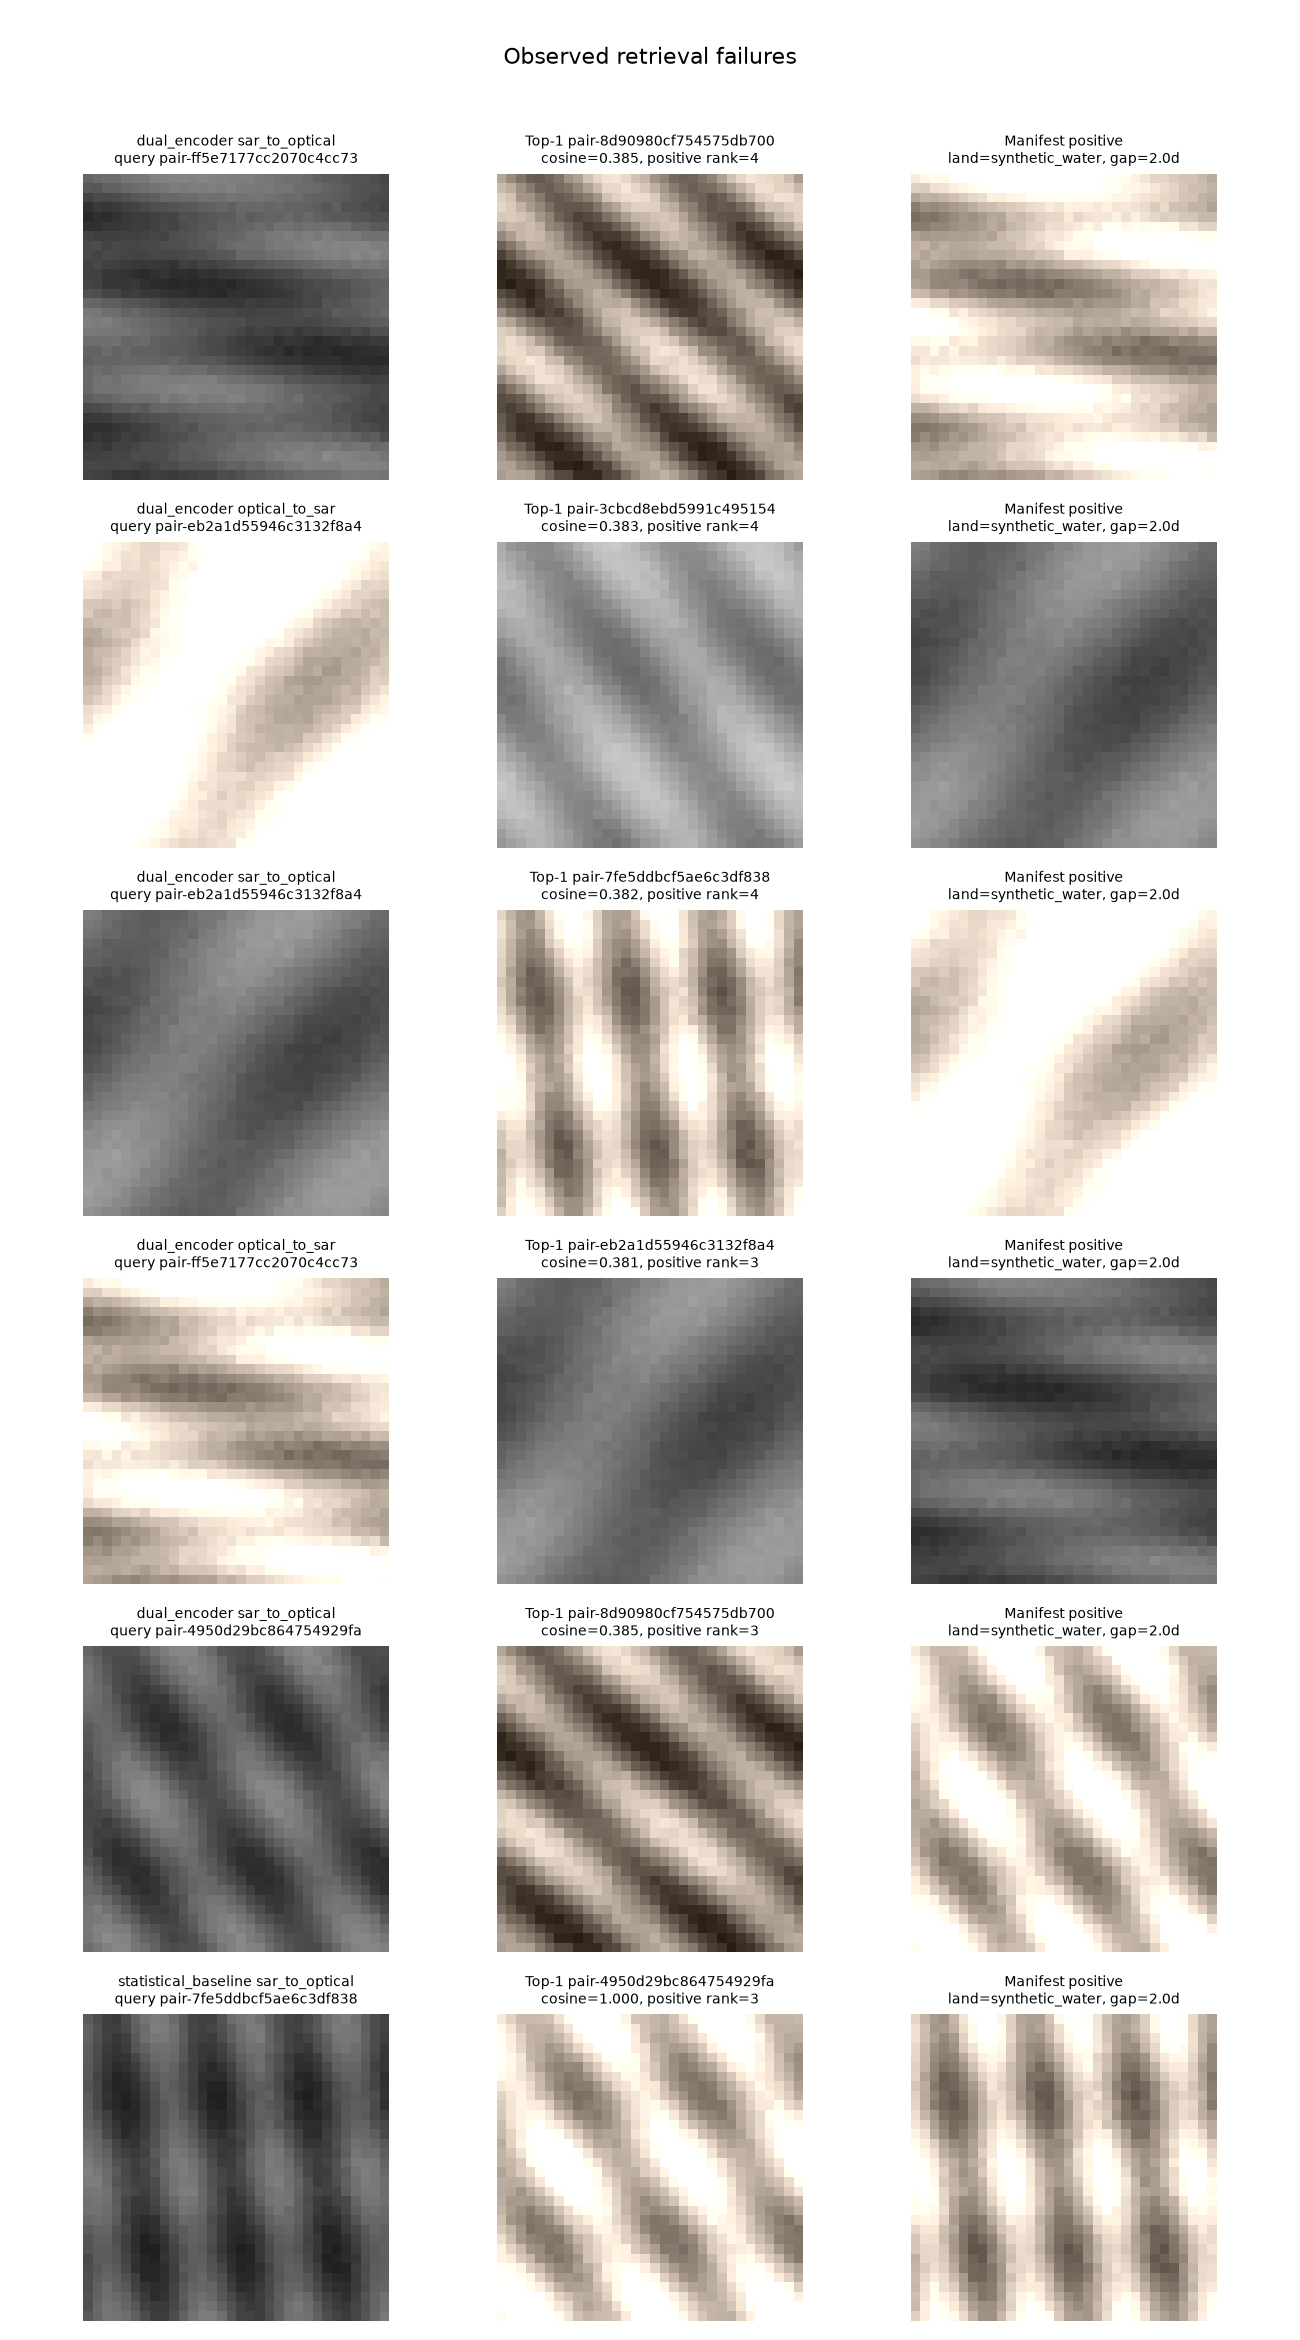

,method,direction,pair_id,positive_rank,top1_id,top1_score,block_id,land_cover
31,dual_encoder,sar_to_optical,pair-ff5e7177cc2070c4cc73,4,pair-8d90980cf754575db700,0.385310,geo-77d3bcd33968,synthetic_water
21,dual_encoder,optical_to_sar,pair-eb2a1d55946c3132f8a4,4,pair-3cbcd8ebd5991c495154,0.382795,geo-77d3bcd33968,synthetic_water
29,dual_encoder,sar_to_optical,pair-eb2a1d55946c3132f8a4,4,pair-7fe5ddbcf5ae6c3df838,0.381987,geo-77d3bcd33968,synthetic_water
23,dual_encoder,optical_to_sar,pair-ff5e7177cc2070c4cc73,3,pair-eb2a1d55946c3132f8a4,0.381351,geo-77d3bcd33968,synthetic_water
26,dual_encoder,sar_to_optical,pair-4950d29bc864754929fa,3,pair-8d90980cf754575db700,0.385421,geo-2696bc3d57a6,synthetic_water
11,statistical_baseline,sar_to_optical,pair-7fe5ddbcf5ae6c3df838,3,pair-4950d29bc864754929fa,0.999973,geo-2696bc3d57a6,synthetic_water
17,dual_encoder,optical_to_sar,pair-dbd8b56a9408557560c2,3,pair-3cbcd8ebd5991c495154,0.388603,geo-2696bc3d57a6,synthetic_water
19,dual_encoder,optical_to_sar,pair-7fe5ddbcf5ae6c3df838,3,pair-4950d29bc864754929fa,0.383439,geo-2696bc3d57a6,synthetic_water
4,statistical_baseline,optical_to_sar,pair-3cbcd8ebd5991c495154,2,pair-dbd8b56a9408557560c2,0.999979,geo-77d3bcd33968,synthetic_water
2,statistical_baseline,optical_to_sar,pair-4950d29bc864754929fa,2,pair-7fe5ddbcf5ae6c3df838,0.999973,geo-2696bc3d57a6,synthetic_water


**Observed in this execution:** 8 synthetic test queries per sensor direction, 18 method/direction query rows with positive rank >1. Inspect `C:\Users\agent\Downloads\coding\CrossSense\outputs\notebook_demo\evaluation\report.html` and `retrievals.csv` for visual and numeric evidence.

In [4]:
display(Image(filename=str(report_dir / "embeddings.png")))
display(Image(filename=str(report_dir / "retrieval_examples.png")))
queries = pd.read_csv(report_dir / "query_metrics.csv")
failures = queries[queries.positive_rank > 1].sort_values("positive_rank", ascending=False)
display(failures.head(12))
display(Markdown(f"**Observed in this execution:** {report['queries_per_direction']} synthetic test queries per sensor direction, {len(failures)} method/direction query rows with positive rank >1. Inspect `{report_dir / 'report.html'}` and `retrievals.csv` for visual and numeric evidence."))

## What this experiment can establish

This run verifies that data preparation, geographic splits, training, checkpoints,
and bidirectional evaluation are connected. Synthetic urban/rural labels and
constructed cloud masks only test diagnostic machinery. Real urban/rural sensor
behavior, seasonal change, noise and acquisition-gap robustness remain unmeasured.
Inspect each geography/land-cover stratum and failure row before making claims.
Repeat with separated real regions and repeated seeds before drawing scientific
conclusions. Official SEN12MS access stopped at the configured archive-size cap;
the India extension contains catalogue metadata only.